In [2]:
!pip install catboost
!pip install lightgbm
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 30.2 MB/s  0:00:03


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder ,StandardScaler
from tqdm import tqdm
from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

In [4]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
train.head()

,id,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents,accident_risk
0,0,urban,2,0.06,35,daylight,rainy,False,True,afternoon,False,True,1,0.13
1,1,urban,4,0.99,35,daylight,clear,True,False,evening,True,True,0,0.35
2,2,rural,4,0.63,70,dim,clear,False,True,morning,True,False,2,0.30
3,3,highway,4,0.07,35,dim,rainy,True,True,morning,False,False,1,0.21
4,4,rural,1,0.58,60,daylight,foggy,False,False,evening,True,False,1,0.56


In [5]:

X = train.drop(['accident_risk', 'id'], axis=1)

y = train['accident_risk']

X_test = test.drop(['id'], axis=1)

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517754 entries, 0 to 517753
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      517754 non-null  int64  
 1   road_type               517754 non-null  object 
 2   num_lanes               517754 non-null  int64  
 3   curvature               517754 non-null  float64
 4   speed_limit             517754 non-null  int64  
 5   lighting                517754 non-null  object 
 6   weather                 517754 non-null  object 
 7   road_signs_present      517754 non-null  bool   
 8   public_road             517754 non-null  bool   
 9   time_of_day             517754 non-null  object 
 10  holiday                 517754 non-null  bool   
 11  school_season           517754 non-null  bool   
 12  num_reported_accidents  517754 non-null  int64  
 13  accident_risk           517754 non-null  float64
dtypes: bool(4), float64(

In [7]:
train.shape

(517754, 14)

In [8]:
train.describe()

,id,num_lanes,curvature,speed_limit,num_reported_accidents,accident_risk
count,517754.000000,517754.000000,517754.000000,517754.000000,517754.000000,517754.000000
mean,258876.500000,2.491511,0.488719,46.112575,1.187970,0.352377
std,149462.849974,1.120434,0.272563,15.788521,0.895961,0.166417
min,0.000000,1.000000,0.000000,25.000000,0.000000,0.000000
25%,129438.250000,1.000000,0.260000,35.000000,1.000000,0.230000
50%,258876.500000,2.000000,0.510000,45.000000,1.000000,0.340000
75%,388314.750000,3.000000,0.710000,60.000000,2.000000,0.460000
max,517753.000000,4.000000,1.000000,70.000000,7.000000,1.000000


In [9]:
train.isna().sum()

,0
id,0
road_type,0
num_lanes,0
curvature,0
speed_limit,0
lighting,0
weather,0
road_signs_present,0
public_road,0
time_of_day,0


In [10]:
train.duplicated().sum()

np.int64(0)

In [11]:
train.drop(columns=['id'], inplace=True)

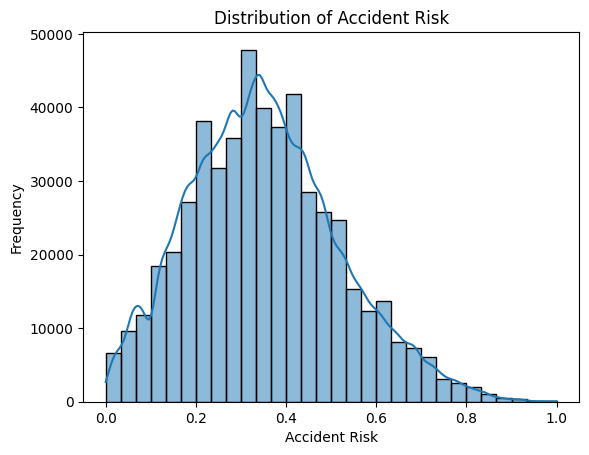

In [12]:
sns.histplot(data=train, x=train['accident_risk'], bins=30, kde=True)
plt.title('Distribution of Accident Risk')
plt.xlabel('Accident Risk')
plt.ylabel('Frequency')
plt.show()

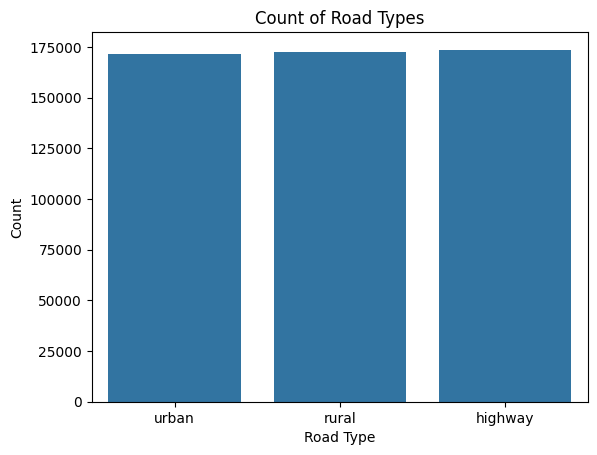

In [13]:
sns.countplot(data=train, x=train['road_type'])
plt.title('Count of Road Types')
plt.xlabel('Road Type')
plt.ylabel('Count')
plt.show()

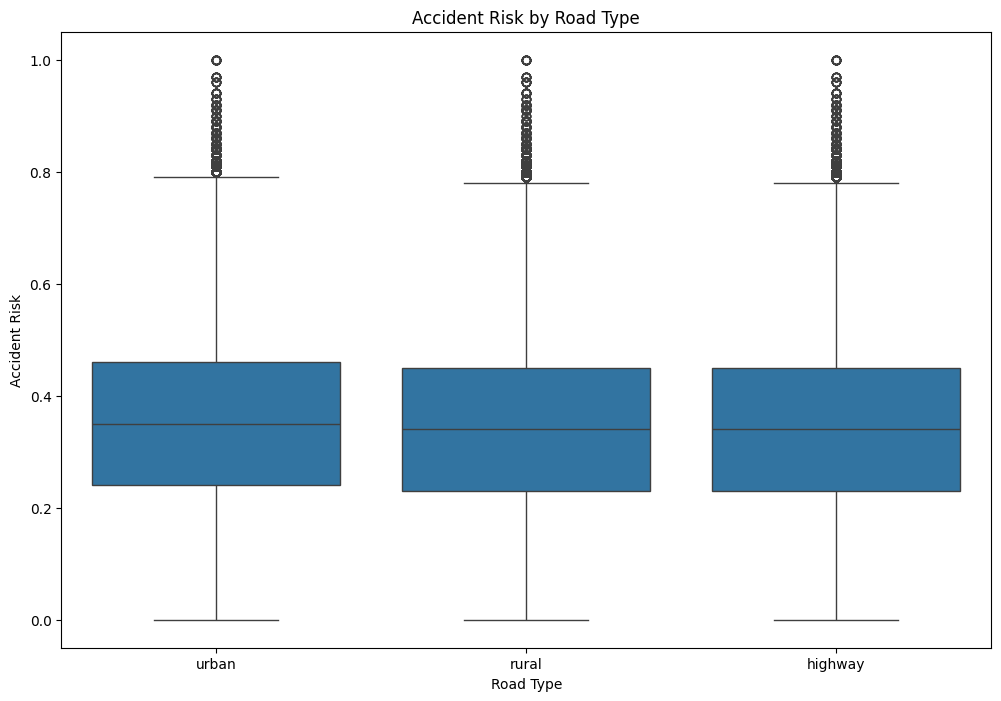

In [14]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=train, x='road_type', y='accident_risk')
plt.title('Accident Risk by Road Type')
plt.xlabel('Road Type')
plt.ylabel('Accident Risk')
plt.show()

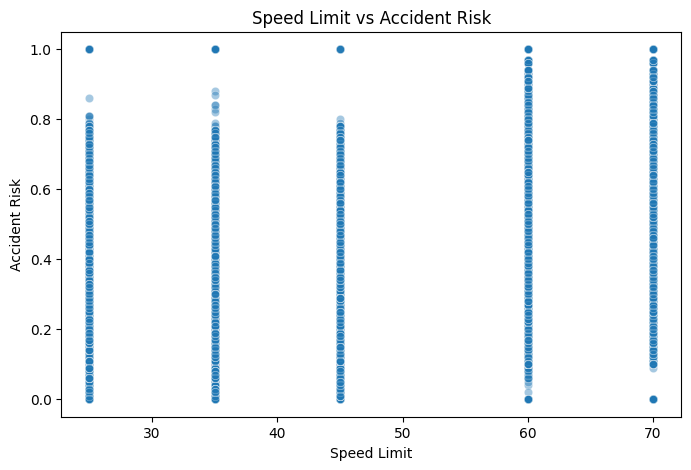

In [15]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=train,
    x='speed_limit',
    y='accident_risk',
    alpha=0.4
)

plt.title('Speed Limit vs Accident Risk')
plt.xlabel('Speed Limit')
plt.ylabel('Accident Risk')

plt.show()

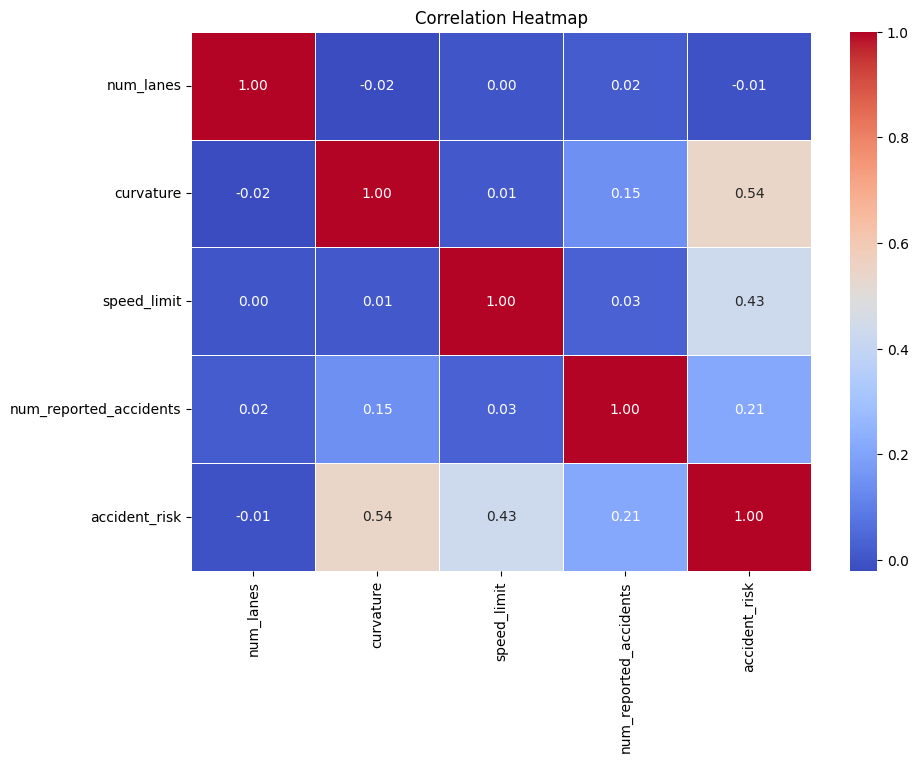

In [16]:
numerical_cols = train.select_dtypes(include=[np.number]).columns

correlation =  train[numerical_cols].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.show()

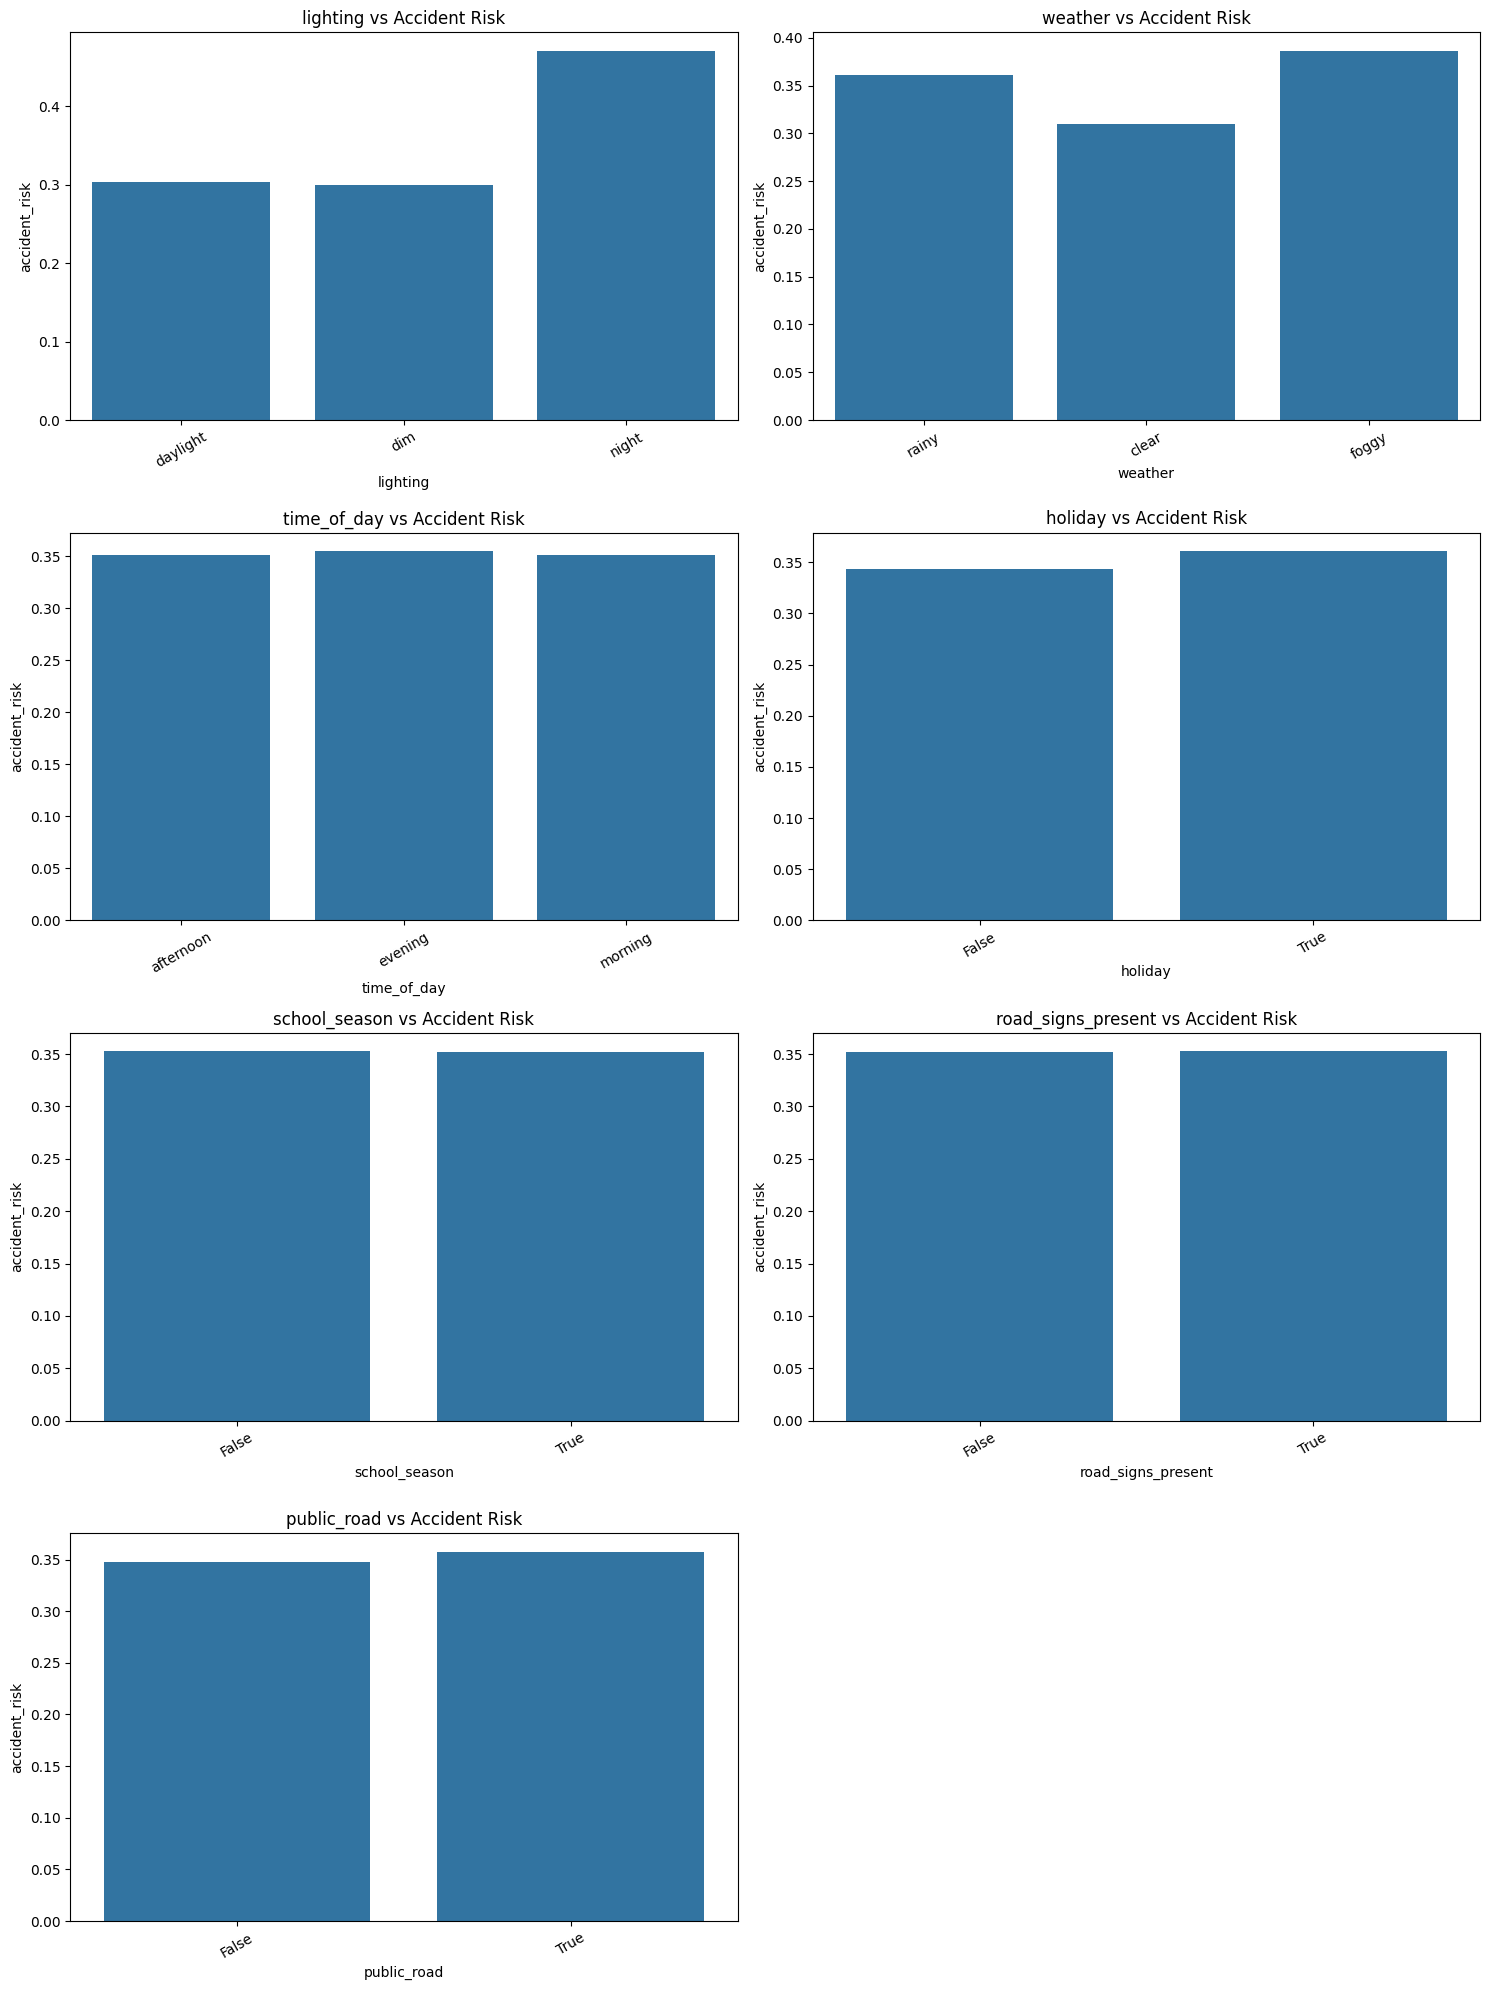

In [17]:
categorical_cols = [
    'lighting',
    'weather',
    'time_of_day',
    'holiday',
    'school_season',
    'road_signs_present',
    'public_road'
]

fig, axes = plt.subplots(4, 2, figsize=(15,20))

axes = axes.flatten()

for i, col in enumerate(categorical_cols):

    sns.barplot(
        data=train,
        x=col,
        y='accident_risk',
        errorbar=None,
        ax=axes[i]
    )

    axes[i].set_title(f'{col} vs Accident Risk')
    axes[i].tick_params(axis='x', rotation=30)

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [18]:
train.select_dtypes(include=['object']).columns

Index(['road_type', 'lighting', 'weather', 'time_of_day'], dtype='object')

In [19]:
 train.select_dtypes(include=['object']).nunique()

,0
road_type,3
lighting,3
weather,3
time_of_day,3


In [20]:
onehot = OneHotEncoder(
    sparse_output=False,
    drop='first',
    handle_unknown='ignore'
).set_output(transform='pandas')
temp=onehot.fit_transform(train[['road_type', 'lighting', 'weather', 'time_of_day']])
train=pd.concat([train, temp], axis=1)
train.drop(columns=['road_type', 'lighting', 'weather', 'time_of_day'], inplace=True)
temp_test = onehot.transform(X_test[['road_type', 'lighting', 'weather', 'time_of_day']])
X_test = pd.concat([X_test, temp_test], axis=1)
X_test.drop(columns=['road_type', 'lighting', 'weather', 'time_of_day'], inplace=True)

In [21]:
X=train.drop(columns=['accident_risk'])
y=train['accident_risk']

In [22]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


In [24]:
# NOTE (sandbox run): KNN / SVM are fit on a random subsample and ExtraTrees is lighter,
# because full-size versions run out of time / memory on 1 CPU + 4 GB RAM.
from sklearn.base import BaseEstimator, RegressorMixin
class SubsampledFit(BaseEstimator, RegressorMixin):
    def __init__(self, base=None, n=30000, seed=0):
        self.base, self.n, self.seed = base, n, seed
    def fit(self, X, y):
        idx = np.random.RandomState(self.seed).choice(len(X), min(self.n, len(X)), replace=False)
        self.base.fit(X[idx], np.asarray(y)[idx]); return self
    def predict(self, X): return self.base.predict(X)

models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":SubsampledFit(KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), n=30000), #  minkowski , euclidean , manhattan
    "SVM":SubsampledFit(SVR(kernel='linear', C=100, gamma=1), n=5000), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=50, min_samples_leaf=10, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [25]:
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

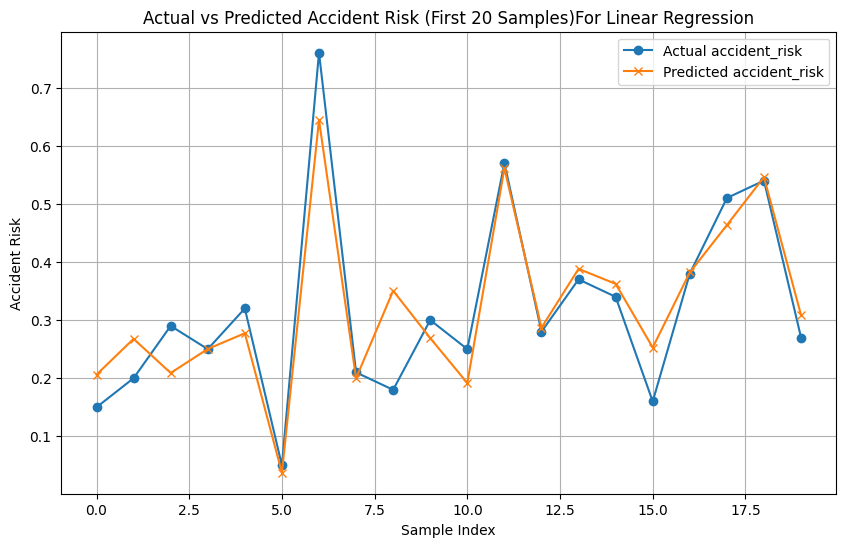

  7%|▋         | 1/15 [00:00<00:08,  1.71it/s]

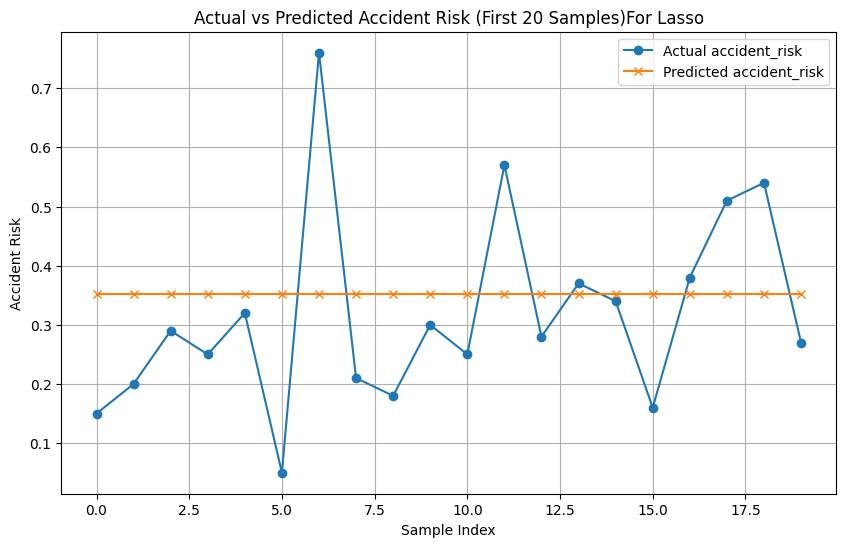

 13%|█▎        | 2/15 [00:00<00:05,  2.21it/s]

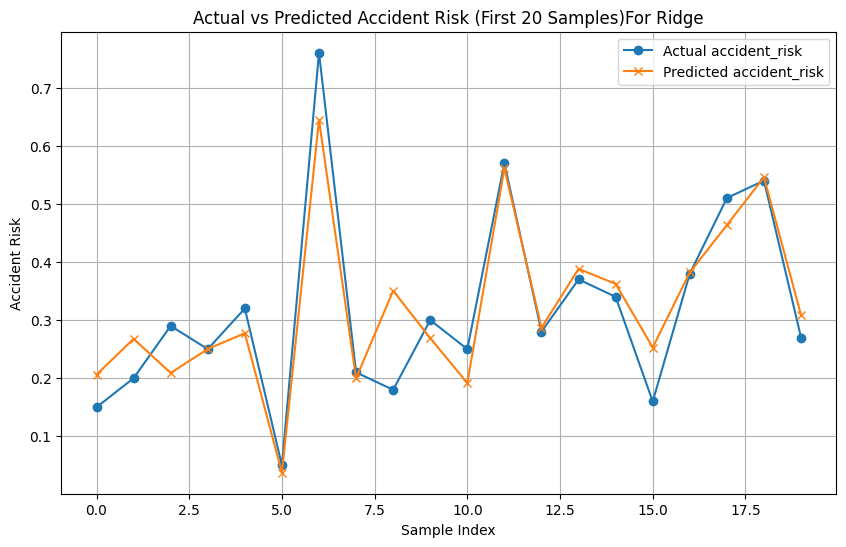

 20%|██        | 3/15 [00:01<00:04,  2.81it/s]

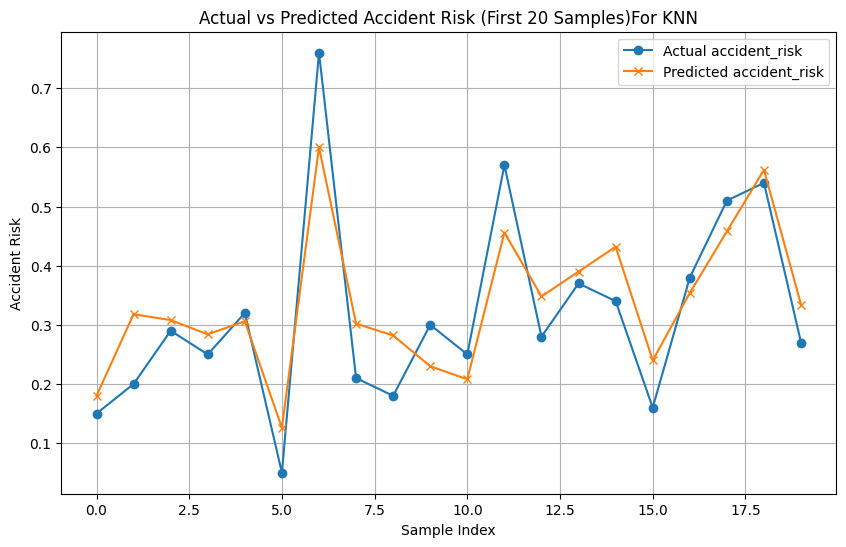

 27%|██▋       | 4/15 [03:43<16:06, 87.84s/it]

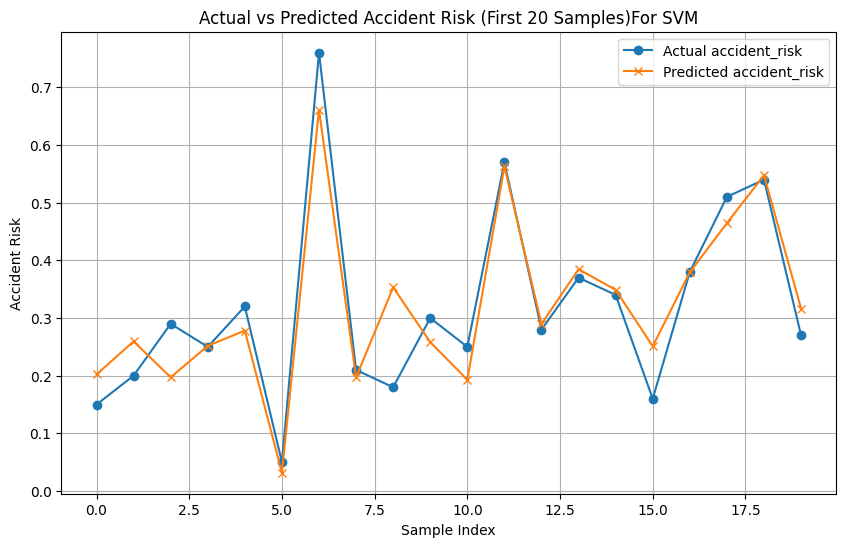

 33%|███▎      | 5/15 [04:59<13:56, 83.68s/it]

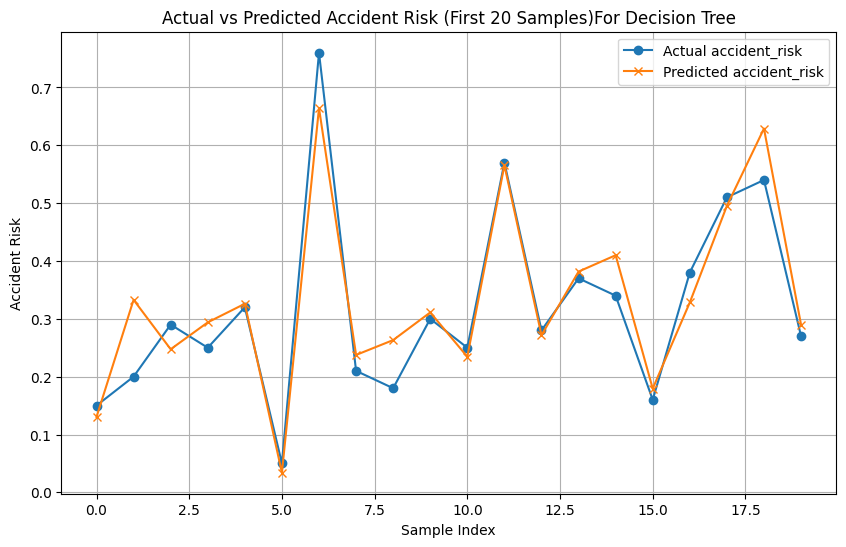

 40%|████      | 6/15 [05:00<08:21, 55.74s/it]

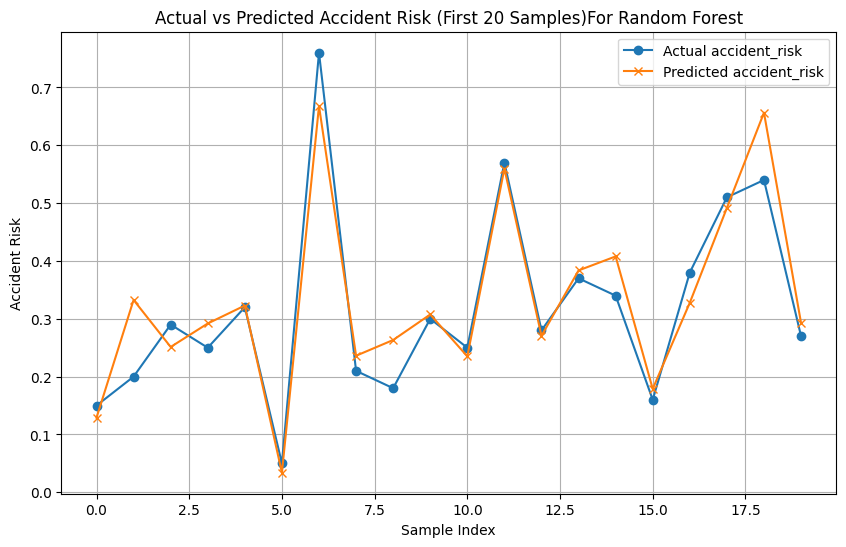

 47%|████▋     | 7/15 [05:58<07:30, 56.33s/it]

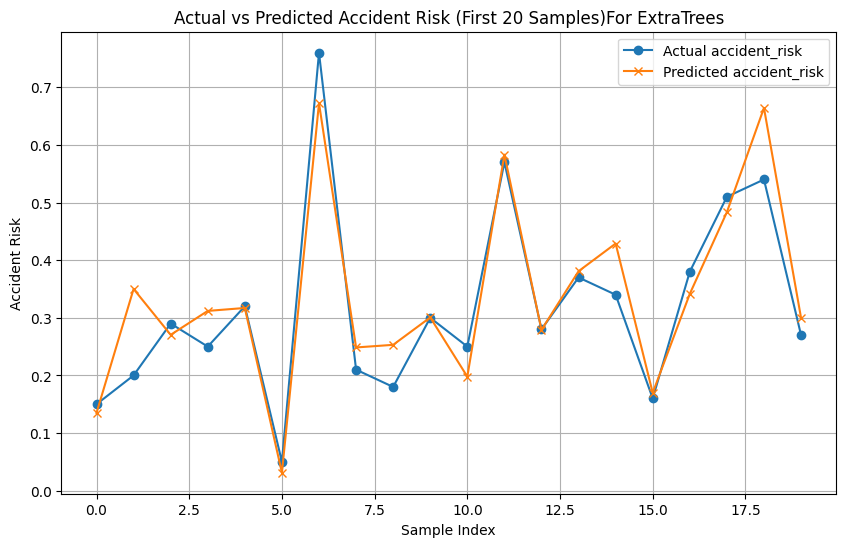

 53%|█████▎    | 8/15 [07:34<08:02, 68.93s/it]

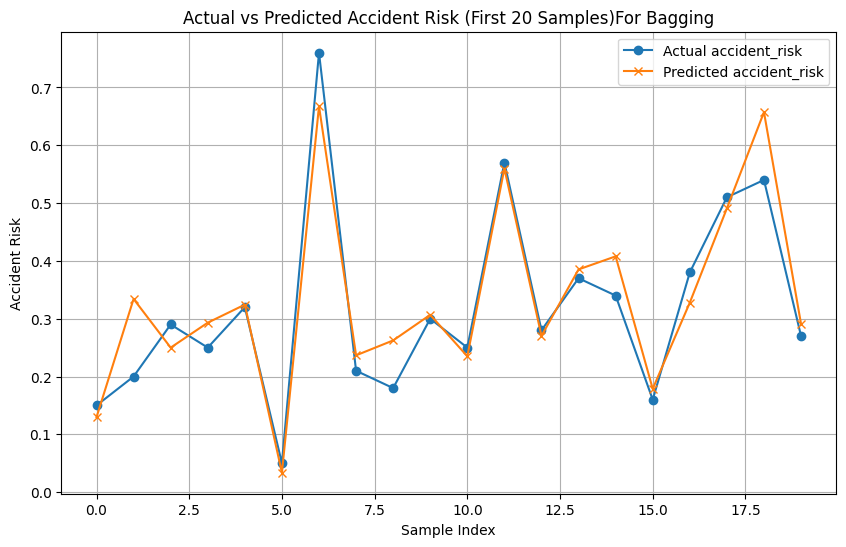

 60%|██████    | 9/15 [08:29<06:26, 64.47s/it]

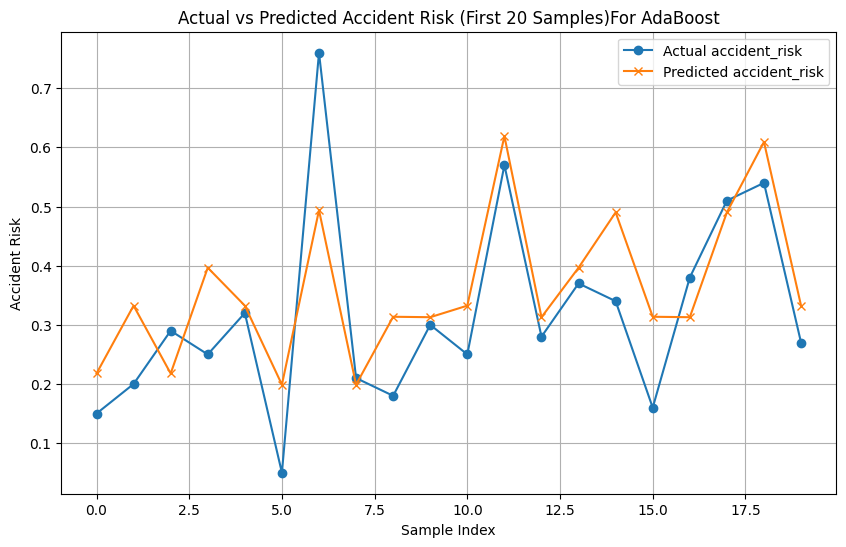

 67%|██████▋   | 10/15 [08:43<04:05, 49.10s/it]

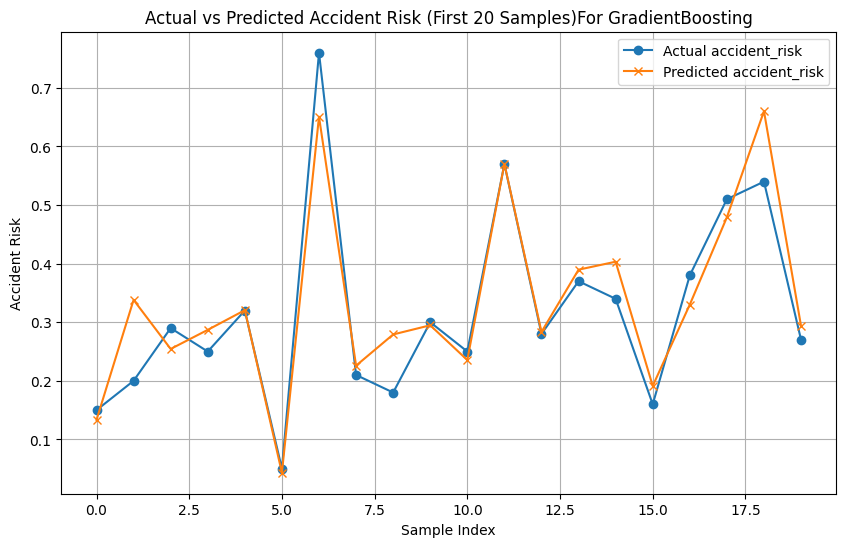

 73%|███████▎  | 11/15 [09:48<03:35, 53.83s/it]

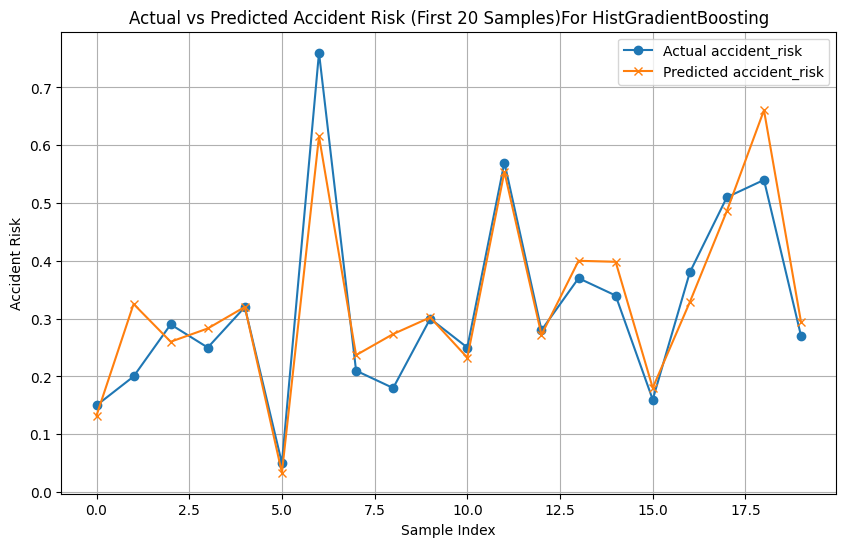

 80%|████████  | 12/15 [09:58<02:02, 40.69s/it]

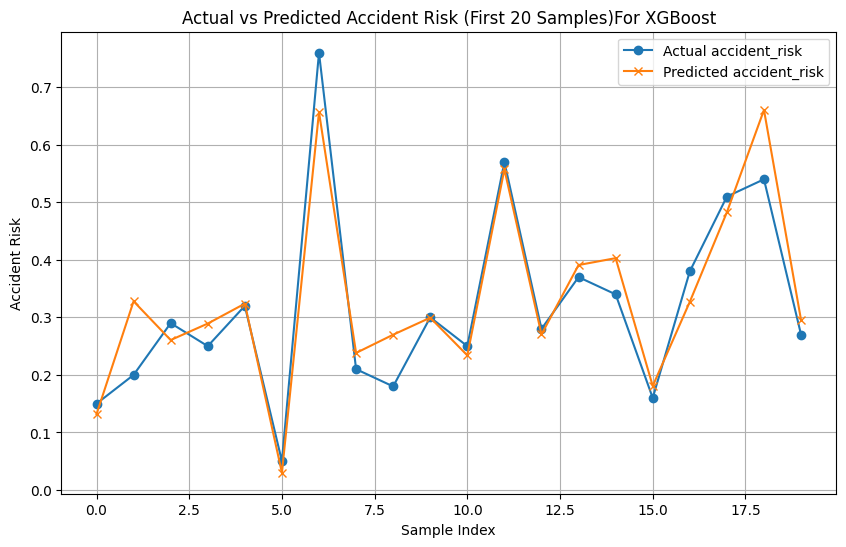

 87%|████████▋ | 13/15 [10:02<00:58, 29.48s/it]

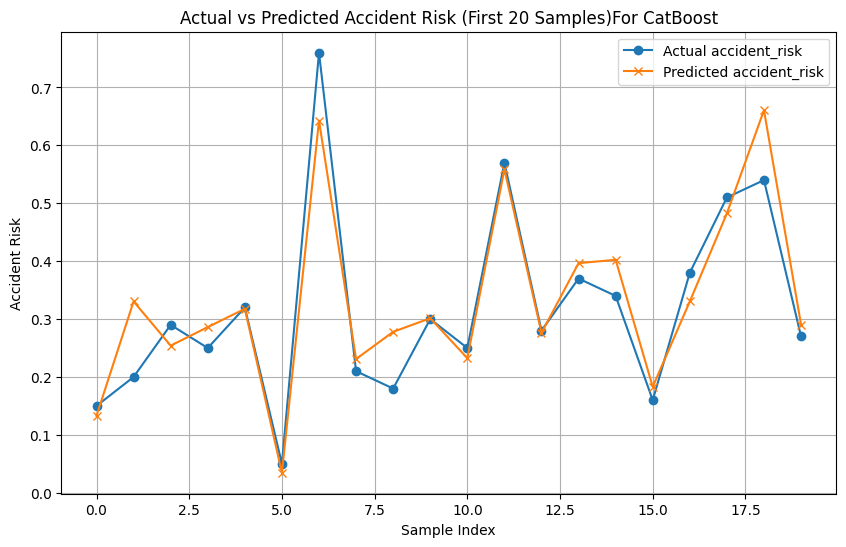

 93%|█████████▎| 14/15 [10:07<00:21, 21.99s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.028868 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 209
[LightGBM] [Info] Number of data points in the train set: 414203, number of used features: 16
[LightGBM] [Info] Start training from score 0.352605


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


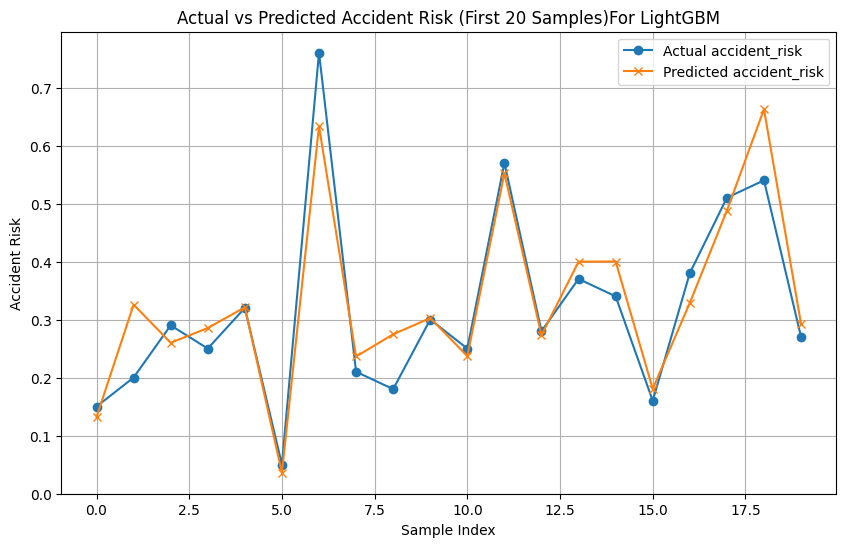

100%|██████████| 15/15 [10:13<00:00, 40.93s/it]


In [26]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_val, y_val)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_val.values[:20]
    y_pred_plot = model.predict(X_val[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual accident_risk', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted accident_risk', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Accident Risk')
    plt.title('Actual vs Predicted Accident Risk (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [27]:
# NOTE (sandbox run): models from the previous cell are freed and each voting model is
# evaluated then deleted, because 3 full-depth Random Forests don't fit in 4 GB RAM together.
import gc
models.clear(); gc.collect()

def eval_into_errors(name, model):
    MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model, X_val, y_val)
    errors[name] = {
        "MAE Train":MAE_Train, "MAE Test":MAE_Test,
        "MSE Train":MSE_Train, "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train, "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train, "R2 Test":R2_Test
    }

# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
for name, weights in [("Voting", None), ("Simple Voting", None), ("Weighted Voting", [2, 1, 2])]:
    vr = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], weights=weights)
    vr.fit(X_train, y_train)
    eval_into_errors(name, vr)
    del vr; gc.collect()


In [28]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_val, y_val)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [29]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Bagging,0.043217,0.043688,0.003090,0.003175,0.055584,0.056346,0.888523,0.885018
Random Forest,0.043220,0.043694,0.003089,0.003175,0.055579,0.056350,0.888545,0.885003
Stacking,0.042153,0.043834,0.003002,0.003183,0.054788,0.056419,0.891691,0.884991
XGBoost,0.043483,0.043762,0.003122,0.003176,0.055875,0.056354,0.887351,0.884985
LightGBM,0.043650,0.043834,0.003146,0.003183,0.056086,0.056419,0.886500,0.884721
HistGradientBoosting,0.043657,0.043853,0.003146,0.003184,0.056085,0.056429,0.886503,0.884679
Decision Tree,0.043346,0.043817,0.003113,0.003197,0.055797,0.056541,0.887667,0.884222
CatBoost,0.043960,0.044098,0.003182,0.003211,0.056407,0.056668,0.885199,0.883702
GradientBoosting,0.044358,0.044453,0.003238,0.003261,0.056903,0.057103,0.883168,0.881910
ExtraTrees,0.037103,0.044459,0.002293,0.003291,0.047888,0.057365,0.917254,0.880825


In [37]:

from sklearn.model_selection import GridSearchCV


bagging = BaggingRegressor(
    estimator=DecisionTreeRegressor(random_state=42),
    random_state=42,
    n_jobs=1
)

param_grid = {
    'n_estimators': [50, 100],
    'estimator__max_depth': [8, 10],
    'estimator__min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=bagging,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=3,
    n_jobs=1,
    verbose=2
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV RMSE:")
print(-grid_search.best_score_)

y_pred = best_model.predict(X_val)

val_rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print("Validation RMSE:", val_rmse)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END estimator__max_depth=8, estimator__min_samples_leaf=1, n_estimators=50; total time=  20.0s
[CV] END estimator__max_depth=8, estimator__min_samples_leaf=1, n_estimators=50; total time=  20.5s
[CV] END estimator__max_depth=8, estimator__min_samples_leaf=1, n_estimators=50; total time=  20.1s
[CV] END estimator__max_depth=8, estimator__min_samples_leaf=1, n_estimators=100; total time=  39.6s
[CV] END estimator__max_depth=8, estimator__min_samples_leaf=1, n_estimators=100; total time=  41.1s
[CV] END estimator__max_depth=8, estimator__min_samples_leaf=1, n_estimators=100; total time=  41.2s
[CV] END estimator__max_depth=8, estimator__min_samples_leaf=2, n_estimators=50; total time=  22.4s
[CV] END estimator__max_depth=8, estimator__min_samples_leaf=2, n_estimators=50; total time=  23.1s
[CV] END estimator__max_depth=8, estimator__min_samples_leaf=2, n_estimators=50; total time=  20.9s
[CV] END estimator__max_depth=8, esti

In [38]:


final_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        criterion='squared_error',
        max_depth=10
    ),
    n_estimators=50,
    random_state=42
)

X_all_scaled = scaler.transform(X)

final_model.fit(X_all_scaled, y)

print("Model trained successfully!")


Model trained successfully!


In [39]:

import joblib
artifacts = {
    "model": final_model,
    "onehot": onehot,
    "scaler": scaler,
    "feature_columns": X.columns.tolist()
}

joblib.dump(artifacts, "accident_risk_model.pkl")

print("Model saved successfully!")


Model saved successfully!


True
